# SAM-6D Usage Example

This notebook walks through the full SAM-6D pipeline using the `SAM6D` class in `src/sam6d.py`.

**Pipeline at a glance:**
1. **Init** — loads SAM + DINOv2 (ISM) and a ViT pose estimation model (PEM), renders CAD templates with BlenderProc, computes reference descriptors
2. **Forward** — given an RGBD frame (RGB image, depth map, camera intrinsics), returns 6DoF poses (R, t), proposal masks, and per-stage confidence scores

Rendered templates and descriptors are cached to `template_dir`, so subsequent runs skip the rendering and embedding steps.

In [1]:
import sys
sys.path.insert(0, "..")  # add repo root if running from a subdirectory

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from src.sam6d import SAM6D

/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


## 1. Configuration

Point `CAD_PATH` at your object's CAD file (`.ply`, `.stl`, `.obj`, etc.).

Checkpoint weights are auto-downloaded on first run if not already present.

**Camera intrinsics** are read directly from the RealSense camera at startup — no manual K matrix needed.

**Depth convention:** the RealSense depth stream is in **millimetres** (z16 = uint16 mm), so `depth_scale` stays `1.0`.

In [2]:
FX, FY, CX, CY = 604.7352294921875, 604.958984375, 430.3172302246094, 245.13461303710938
K = np.array([
    [FX,  0,  CX],
    [0,  FY,  CY],
    [0,   0,   1],
], dtype=np.float32)

In [3]:
import pyrealsense2 as rs
import numpy as np

SERIAL_NUMBER = '243322070950'
WIDTH = 848
HEIGHT = 480
FPS = 30
DEPTH_EXPOSURE_US = 6000
LASER_POWER_FRAC = 0.5
DEPTH_MIN_M = 0.0 # 0 min
DEPTH_MAX_M = 0.5 # 16 max
# ACCURACY = 1 # not supported
# MOTION_RANGE = 1 # not supported
DEPTH_GAIN = 16 # intel recommends keeping this at the lowest value for depth accuracy
COLOR_EXPOSURE_US = 166//2    # tune: lower = darker/sharper motion, higher = brighter
COLOR_WHITE_BALANCE_K = 4600  # tune: ~2800 warm, ~4600 neutral, ~6500 cool
DISPARITY_SHIFT = 50

rs_pipeline = rs.pipeline()
rs_config = rs.config()

rs_context = rs.context()
if len(rs_context.query_devices()) == 0:
    raise RuntimeError(
        "[Camera] No RealSense devices detected. "
        "Check USB connection and that Terminal has Camera permission "
        "(System Settings → Privacy & Security → Camera)."
    )

rs_config.enable_device(SERIAL_NUMBER)

rs_config.enable_stream(rs.stream.depth, WIDTH, HEIGHT, rs.format.z16, FPS)
rs_config.enable_stream(rs.stream.color, WIDTH, HEIGHT, rs.format.rgb8, FPS)

# Start pipeline first to get device access
rs_profile = rs_pipeline.start(rs_config)

# ==========================================
# DISPARITY SHIFT (ADVANCED MODE)
# ==========================================
device = rs_profile.get_device()
advanced_mode = rs.rs400_advanced_mode(device)

if advanced_mode.is_enabled():
    print(f"Advanced mode is active. Setting disparity shift to {DISPARITY_SHIFT}...")
    depth_table = advanced_mode.get_depth_table()
    depth_table.disparityShift = DISPARITY_SHIFT 
    advanced_mode.set_depth_table(depth_table)
else:
    print("Advanced mode is NOT enabled on this device. Disparity shift skipped.")
# ==========================================

rs_align = rs.align(rs.stream.color) 

# Depth sensor
depth_sensor = rs_profile.get_device().first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

depth_sensor.set_option(rs.option.emitter_enabled, 1) 

# depth exposure 
if depth_sensor.supports(rs.option.enable_auto_exposure):
    print('Auto exposure supported.')
    depth_sensor.set_option(rs.option.enable_auto_exposure, 0)

if depth_sensor.supports(rs.option.exposure):
    print('Exposure supported.')
    depth_sensor.set_option(rs.option.exposure, DEPTH_EXPOSURE_US)

# depth gain
if depth_sensor.supports(rs.option.gain):
    print('Gain supported.')
    depth_sensor.set_option(rs.option.gain, DEPTH_GAIN)

# laser power 
if depth_sensor.supports(rs.option.laser_power):
    print('Laser power supported.')
    laser_range = depth_sensor.get_option_range(rs.option.laser_power)
    laser_power = laser_range.min + LASER_POWER_FRAC * (laser_range.max - laser_range.min)
    print(laser_power)
    depth_sensor.set_option(rs.option.laser_power, laser_power)

# Color sensor — lock exposure and white balance for consistent color across frames
color_sensor = rs_profile.get_device().first_color_sensor()

if color_sensor.supports(rs.option.enable_auto_exposure):
    color_sensor.set_option(rs.option.enable_auto_exposure, 0)
    color_sensor.set_option(rs.option.exposure, COLOR_EXPOSURE_US)
    print(f'Color exposure locked at {COLOR_EXPOSURE_US} us')

if color_sensor.supports(rs.option.enable_auto_white_balance):
    color_sensor.set_option(rs.option.enable_auto_white_balance, 0)
    color_sensor.set_option(rs.option.white_balance, COLOR_WHITE_BALANCE_K)
    print(f'Color white balance locked at {COLOR_WHITE_BALANCE_K} K')

color_profile = rs_profile.get_stream(rs.stream.color)
# Camera Matrix (K) Extracted for Computer Vision
intr = color_profile.as_video_stream_profile().get_intrinsics()
K = np.array([[intr.fx,       0, intr.ppx], 
              [      0, intr.fy, intr.ppy],
              [      0,       0,         1],], dtype=np.float32)
print(K)

# capture a rgbd frame
frames = rs_pipeline.wait_for_frames(timeout_ms=5000)
frames.keep() # what does keep() do?
aligned = rs_align.process(frames)

# separate the color and depth frames
color_frame = aligned.get_color_frame()
depth_frame = aligned.get_depth_frame()

# apply post-processing to depth frame
# depth_frame = rs_threshold.process(depth_frame)
# depth_frame = rs_spatial.process(depth_frame)
# depth_frame = rs_temporal.process(depth_frame)
# depth_frame = rs_hole_fill.process(depth_frame)

rgb = np.asanyarray(color_frame.get_data())
depth_raw = np.asanyarray(depth_frame.get_data())
depth = depth_raw.astype(np.float32) * depth_scale

rs_pipeline.stop()

ModuleNotFoundError: No module named 'pyrealsense2'

In [ ]:
# --- Paths --- adjust these to your setup
CAD_PATH     = "/home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-r.stl"
TEMPLATE_DIR = "./sam6d_templates"   # rendered views + descriptors are cached here

# Camera intrinsic matrix (3x3) — replace with your actual camera K
# K = np.array([
#     [572.4114,   0.    , 325.2611],
#     [  0.    , 573.5704, 242.0490],
#     [  0.    ,   0.    ,   1.    ],
# ], dtype=np.float32)

DEPTH_SCALE = 1000.0   # multiply raw depth pixels → mm (1.0 if already mm)

# Optional: apply a solid color to colorless meshes (e.g. STL files without texture)
MESH_COLOR = (int(0.4*255), int(0.4*255), int(0.4*255))  # RGB 0-255, or None to leave as-is

# Optional: use flat shading so that flat faces render flat (helps for CAD/STL)
FLAT_SHADING = True

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cuda


## 2. Initialize SAM6D

Initialization renders 42 BlenderProc templates (skipped if already cached), computes ISM reference descriptors, and pre-extracts PEM template point-cloud features.

Key parameters:
- `sam_model_type`: `"vit_h"` (default, best quality ~2.4 GB), `"vit_l"` / `"vit_b"` (**~358 MB each — use these when VRAM is tight**)
- `n_template_view`: how many of the 42 rendered views PEM uses (42 = all, fewer = faster)
- `det_score_thresh`: ISM proposals below this score are dropped before pose estimation
- `confidence_thresh`: minimum DINOv2 semantic similarity to even consider a proposal
- `mesh_color`: RGB tuple (0–255) applied to colorless meshes (e.g. STL); `None` leaves textures as-is
- `flat_shading`: set `True` to disable normal interpolation so flat faces render flat
- `roughness`: Principled BSDF roughness — `0.0` = mirror/glossy, `1.0` = fully matte (`None` = Blender default 0.5)
- `metallic`: Principled BSDF metallic weight — `0.0` = plastic, `1.0` = metallic conductor (`None` = Blender default 0.0)
- `light_energy`: point light brightness in watts (default `1000`)
- `min_component_area_ratio`: drop disconnected mask blobs smaller than this fraction of the largest blob (0 = off)
- `mask_overlap_thresh`: suppress the lower-scoring detection when two masks overlap by more than this fraction of the smaller mask's area (0 = off)

**Memory management options** (all default `False`):
- `half_precision`: load SAM, DINOv2, and PEM in **fp16** — cuts weight VRAM ~50% (~2.5 GB saved); slight accuracy risk
- `auto_offload`: automatically move all models to CPU after each `forward()` call, freeing ~5 GB before FoundationPose runs; call `reload_to_gpu()` before the next forward
- `empty_cache_between_stages`: call `torch.cuda.empty_cache()` after SAM, DINOv2, and PEM stages to return fragmented buffers to the allocator

In [ ]:
model = SAM6D(
    cad_path=CAD_PATH,
    device=DEVICE,

    # Segmentor
    # sam_model_type="vit_b",  # "vit_b" / "vit_l" use ~358 MB vs "vit_h" at 2.4 GB
    sam_model_type="vit_h",
    stability_score_thresh=0.96,

    # Template rendering
    template_dir=TEMPLATE_DIR,
    reset_templates=False,   # set True to force re-render
    mesh_color=MESH_COLOR,   # RGB (0-255) for colorless meshes, or None
    flat_shading=FLAT_SHADING,  # True = flat faces render flat
    roughness=0.8,              # 0.0 = mirror/glossy, 1.0 = fully matte
    metallic=0.0,               # 0.0 = plastic/dielectric, 1.0 = metallic
    light_energy=600,          # point light brightness in watts

    # Matching / filtering
    det_score_thresh=0.45,   # minimum combined ISM score: (semantic + appearance + geometric×visible_ratio) / (2 + visible_ratio)
    confidence_thresh=0.25,  # minimum DINOv2 CLS-token semantic similarity; proposals below this are discarded before appearance/geometric scoring runs
    visible_thred=0.15,
    n_template_view=42,
    min_component_area_ratio=0.005,  # drop disconnected mask blobs < 0.5% of largest
    mask_overlap_thresh=0.9,         # suppress lower-scoring mask if overlap > 90%
    pose_score_thresh=0.1,           # drop detections with pose score below this (0=off)

    # Memory management — uncomment to reduce VRAM usage
    half_precision=True,             # fp16 weights: ~50% less VRAM, slight accuracy risk
    # auto_offload=True,               # free ~5 GB after each forward(); reload with model.reload_to_gpu()
    # empty_cache_between_stages=True, # torch.cuda.empty_cache() between SAM / DINOv2 / PEM stages
)

load pre-trained checkpoint from: /home/joon/Projects/cnos/checkpoints/mae_pretrain_vit_base.pth


## 3. Load RGBD Data

Replace the paths below with your actual RGB image and depth map.
The depth map should be a single-channel image (uint16 or float) with values in mm.

In [ ]:
# --- Load your RGBD frame here ---
import pickle

# Load an object from a file
with open('/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/single_rgbd.pkl', 'rb') as file:
    loaded_data = pickle.load(file)

rgb   = loaded_data[0]
depth = loaded_data[1]

print(f"RGB shape:   {rgb.shape}")
print(f"Depth shape: {depth.shape}")
print(f"Depth range: {depth.min():.1f} – {depth.max():.1f} mm")

RGB shape:   (480, 848, 3)
Depth shape: (480, 848)
Depth range: 0.0 – 0.2 mm


## 4. Run Forward Pass

`forward()` accepts an RGB array/PIL image, a depth map (mm), and camera intrinsics, and returns a dict with poses and all intermediate scores.

In [ ]:
results = model(rgb, depth, K, depth_scale=DEPTH_SCALE)   # or model.forward(...)

N = len(results["poses"])
print(f"Detections passing threshold: {N}")
print()
print(f"masks:             {results['masks'].shape}         # [N, H, W] bool")
print(f"boxes:             {results['boxes'].shape}         # [N, 4] xyxy")
print(f"ism_scores:        {results['ism_scores'].shape}    # [N] final ISM confidence")
print(f"semantic_scores:   {results['semantic_scores'].shape}")
print(f"appe_scores:       {results['appe_scores'].shape}")
print(f"geometric_scores:  {results['geometric_scores'].shape}")
print(f"pred_R:            {results['pred_R'].shape}        # [N, 3, 3]")
print(f"pred_t:            {results['pred_t'].shape}        # [N, 3]  (mm)")
print(f"pose_scores:       {results['pose_scores'].shape}")

if N > 0:
    best = np.argmax(results['pose_scores'])
    print(f"\nBest pose (detection {best}, score={results['pose_scores'][best]:.3f}):")
    print(f"  R =\n{results['pred_R'][best]}")
    print(f"  t = {results['pred_t'][best]} mm")

Detections passing threshold: 1

masks:             (1, 480, 848)         # [N, H, W] bool
boxes:             (1, 4)         # [N, 4] xyxy
ism_scores:        (1,)    # [N] final ISM confidence
semantic_scores:   (1,)
appe_scores:       (1,)
geometric_scores:  (1,)
pred_R:            (1, 3, 3)        # [N, 3, 3]
pred_t:            (1, 3)        # [N, 3]  (mm)
pose_scores:       (1,)

Best pose (detection 0, score=0.414):
  R =
[[ 0.7985187   0.08769232 -0.5955481 ]
 [-0.54876137 -0.30062896 -0.7800535 ]
 [-0.24744433  0.94970113 -0.1919352 ]]
  t = [-155.72713  245.7495  -258.5295 ] mm


## 5. Memory Management Before FoundationPose

SAM6D holds ~5 GB of VRAM persistently (SAM ViT-H 2.4 GB + DINOv2 1.2 GB + PEM 1.3 GB). Since SAM6D and FoundationPose run sequentially, you can reclaim that memory before FoundationPose starts.

**Option A — automatic** (`auto_offload=True` at init time):
```python
model = SAM6D(..., auto_offload=True)
results = model(rgb, depth, K)   # models offloaded to CPU automatically on return
fp_results = fp(rgb, depth, K, results)
model.reload_to_gpu()            # bring models back before the next forward()
```

**Option B — manual control** (call explicitly when you need it):
```python
results = model(rgb, depth, K)
model.offload_to_cpu()           # ~5 GB freed immediately
fp_results = fp(rgb, depth, K, results)
model.reload_to_gpu()            # reload before next frame
```

The cell below shows how to measure the VRAM freed.

In [ ]:
before_mb = torch.cuda.memory_allocated() / 1024**2
print(f"VRAM before offload: {before_mb:.0f} MB")

model.offload_to_cpu()

after_mb = torch.cuda.memory_allocated() / 1024**2
print(f"VRAM after  offload: {after_mb:.0f} MB  ({before_mb - after_mb:.0f} MB freed)")

# FoundationPose can now use the freed memory.
# Uncomment to reload SAM6D models before the next forward():
# model.reload_to_gpu()

VRAM before offload: 2299 MB
VRAM after  offload: 9 MB  (2290 MB freed)


## 5. Visualize Detections

Each detection is shown with its ISM mask overlay and bounding box. The best-scoring pose is highlighted.

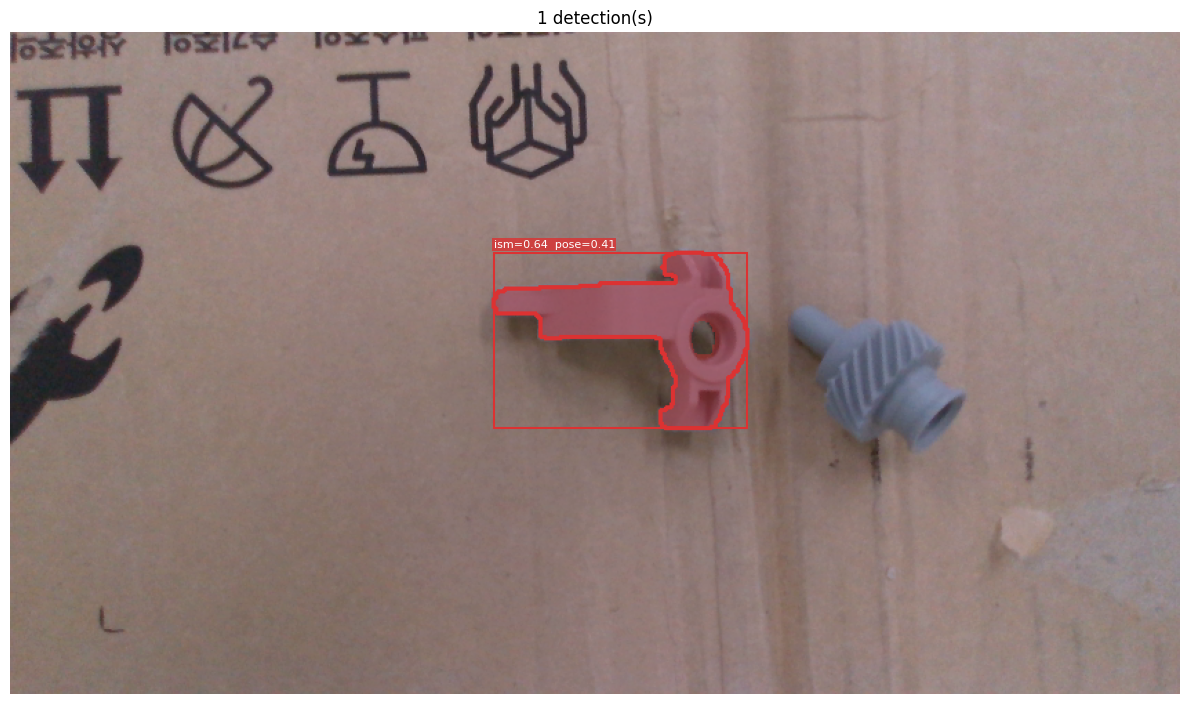

In [ ]:
def visualize_detections(rgb, results, alpha=0.4):
    import cv2

    COLORS = [
        "#DC3232", "#1EC8C8", "#3264DC", "#32B432",
        "#A032DC", "#F08C1E", "#E650B4", "#C8C828",
    ]

    def hex_to_rgb(h):
        h = h.lstrip("#")
        return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)])

    masks       = results["masks"]       # [N, H, W] bool
    boxes       = results["boxes"]       # [N, 4] xyxy
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    colors = [hex_to_rgb(COLORS[i % len(COLORS)]) for i in range(len(masks))]

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        mask = masks[i].astype(bool)
        overlay[mask] = (1 - alpha) * overlay[mask] + alpha * colors[i]

    canvas = overlay.astype(np.uint8)
    for i in order:
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, colors[i].tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s) in enumerate(zip(boxes, ism_scores, pose_scores)):
        x1, y1, x2, y2 = box
        color = colors[i] / 255.0
        lw = 1.5
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=lw, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        label = f"ism={ism_s:.2f}  pose={pose_s:.2f}"
        ax.text(
            x1, y1 - 4, label,
            color="white", fontsize=8,
            bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"),
        )

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s)")
    plt.tight_layout()
    plt.show()


visualize_detections(rgb, results)

## 6. Project Poses onto Image

All detections are overlaid on the image with their CAD point cloud and coordinate axes.
The **best-scoring** detection uses orange dots and thick axes; others use grey dots and thin axes.

Axes convention: **X = blue**, **Y = green**, **Z = red** (OpenCV camera frame).
Adjust `axis_len_mm` to match your object's scale.

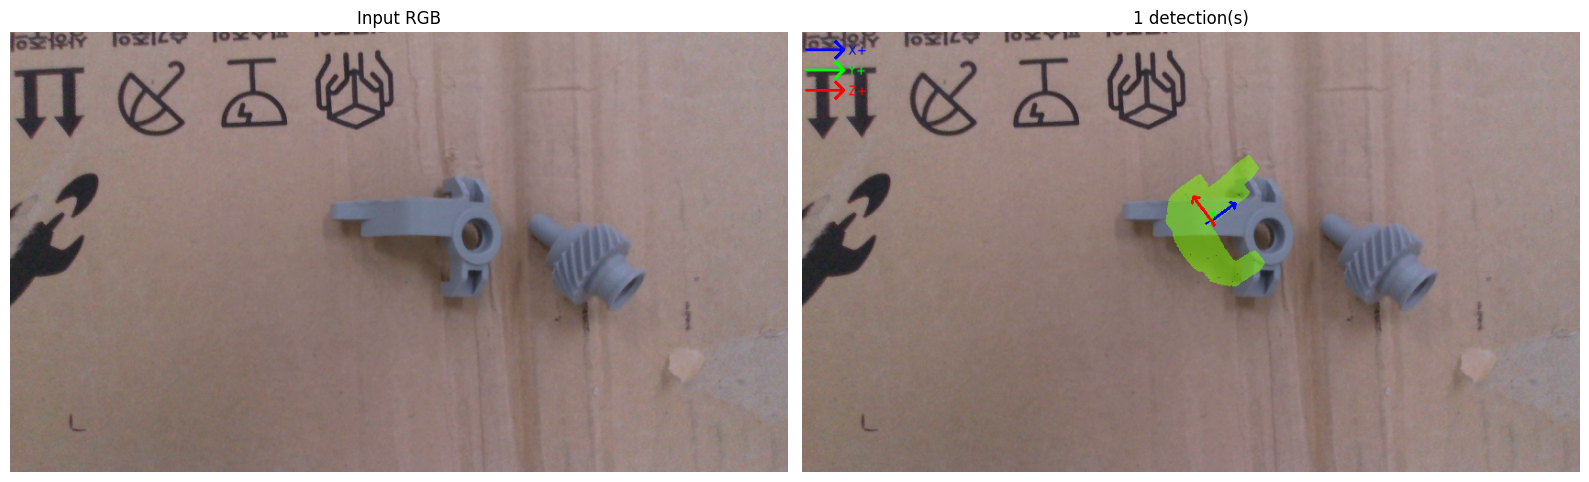

In [ ]:
def project_all_poses(rgb, results, K, cad_path, n_pts=1024, axis_len_mm=10):
    import trimesh, cv2

    poses       = results['poses']
    pose_scores = results['pose_scores']
    if len(poses) == 0:
        print('No detections — nothing to project.')
        return

    mesh    = trimesh.load_mesh(cad_path)
    pts_mm  = mesh.sample(n_pts).astype(np.float32)
    best_i  = int(np.argmax(pose_scores))
    origin  = mesh.centroid.astype(np.float32)  # use centroid, not [0,0,0]

    fx, fy, cx, cy = K[0,0], K[1,1], K[0,2], K[1,2]
    H, W = rgb.shape[:2]

    def project(pts_cam):
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        return u, v, valid

    def pt2img(p_obj, R, t_mm):
        p_cam = R @ p_obj + t_mm
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx),
                int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        """Draw a dashed line from p1 to p2."""
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx**2 + dy**2) ** 0.5))
        for i in range(0, dist, gap * 2):
            t0, t1 = i / dist, min((i + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas = rgb.copy()
    overlay = canvas.copy()

    # --- point cloud ---
    for idx, pose in enumerate(poses):
        R, t = pose['R'], pose['t']
        pts_cam = (R @ pts_mm.T).T + t[None, :]
        u, v, valid = project(pts_cam)
        dot_color = (255 // 2, 255, 0)
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 1, dot_color, -1)

    canvas = cv2.addWeighted(canvas, 0.5, overlay, 0.5, 0)

    # --- axes ---
    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_LEN = 0.35   # negative stub = 35% of axis_len_mm

    for idx, pose in enumerate(poses):
        R, t = pose['R'], pose['t']
        o_img = pt2img(origin, R, t)
        if o_img is None:
            continue
        thickness = 2

        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3); unit[axis_idx] = 1.0

            # positive direction: solid arrow
            tip = pt2img(origin + unit * axis_len_mm, R, t)
            if tip is not None:
                cv2.arrowedLine(canvas, o_img, tip, color, thickness, tipLength=0.2)

            # negative direction: dashed stub so you can read +/- orientation
            neg_tip = pt2img(origin - unit * axis_len_mm * NEG_LEN, R, t)
            if neg_tip is not None:
                draw_dashed_line(canvas, o_img, neg_tip, color, thickness)

    # --- legend ---
    for i, (lbl, color) in enumerate([("X+", (0,0,255)), ("Y+", (0,255,0)), ("Z+", (255,0,0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)  # neg stub sample
        cv2.putText(canvas, lbl, (50, y + 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(
        f"{len(poses)} detection(s)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


project_all_poses(rgb, results, K, CAD_PATH, n_pts=4096*4)

## 7. Inspect Intermediate Score Distributions

SAM-6D's ISM computes three complementary scores per proposal before passing to PEM:
- **Semantic** — DINOv2 CLS-token cosine similarity to reference templates
- **Appearance** — masked patch-token similarity (texture/appearance)
- **Geometric** — IoU between projected template point cloud and proposal bbox (depth-aware)

Inspecting these independently is useful for diagnosing failures.

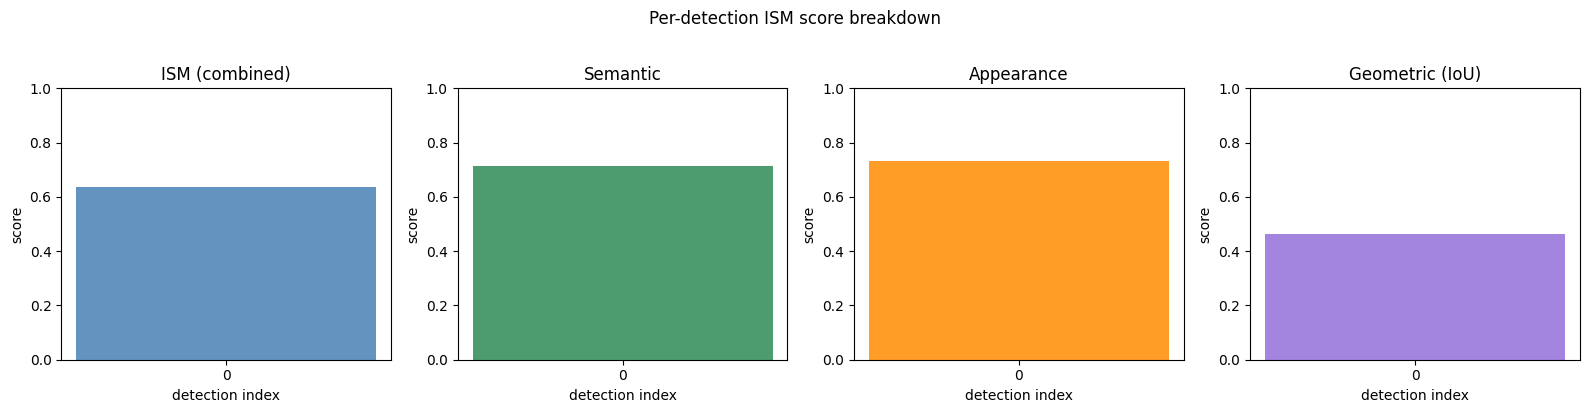

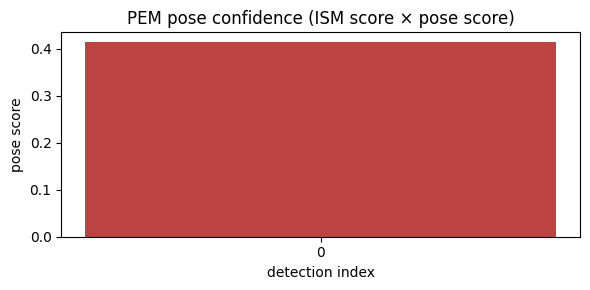

In [ ]:
if len(results["ism_scores"]) > 0:
    N = len(results["ism_scores"])
    det_ids = np.arange(N)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)

    score_data = [
        ("ISM (combined)",  results["ism_scores"],       "steelblue"),
        ("Semantic",        results["semantic_scores"],  "seagreen"),
        ("Appearance",      results["appe_scores"],      "darkorange"),
        ("Geometric (IoU)", results["geometric_scores"], "mediumpurple"),
    ]

    for ax, (title, vals, color) in zip(axes, score_data):
        ax.bar(det_ids, vals, color=color, alpha=0.85)
        ax.set_title(title)
        ax.set_xlabel("detection index")
        ax.set_ylabel("score")
        ax.set_xticks(det_ids)
        ax.set_ylim(0, 1)

    plt.suptitle("Per-detection ISM score breakdown", y=1.02)
    plt.tight_layout()
    plt.show()

    # PEM confidence
    fig, ax = plt.subplots(figsize=(max(6, N * 0.8), 3))
    ax.bar(det_ids, results["pose_scores"], color="firebrick", alpha=0.85)
    ax.set_title("PEM pose confidence (ISM score × pose score)")
    ax.set_xlabel("detection index")
    ax.set_ylabel("pose score")
    ax.set_xticks(det_ids)
    plt.tight_layout()
    plt.show()
else:
    print("No detections to display.")

## 8. FoundationPose Pose Refinement

[FoundationPose](https://github.com/NVlabs/FoundationPose) refines the initial SAM-6D pose estimates using iterative RGB-D re-rendering and a learned score network. It operates in two modes:

- **Registration** (`refine_from_sam6d` / `__call__`) — given a new frame with SAM-6D detections, registers FoundationPose on each detection's mask and returns a refined 4×4 pose matrix (translation in **metres**).
- **Tracking** (`track`) — on subsequent frames, tracks each registered object without re-running SAM-6D.

**Prerequisites before running:**
1. Build the `mycpp` C++ extension (needed for pose hypothesis clustering):
   ```bash
   cd FoundationPose-main/mycpp && mkdir -p build && cd build \
     && cmake .. -DPYTHON_EXECUTABLE=$(which python) && make -j4
   ```
2. Model weights (~300 MB) are auto-downloaded from Google Drive on first run into `FoundationPose-main/weights/`. To download manually, see `FoundationPose-main/readme.md`.

In [ ]:
from src.foundationpose import FoundationPoseRefiner

fp = FoundationPoseRefiner(
    cad_path=CAD_PATH,
    device=DEVICE,

    # Mesh units → metres conversion (1/1000 = mm→m, which is the default for STL/CAD files)
    mesh_scale=1/1000.0,

    # Refinement iterations: more = slower but more accurate
    est_refine_iter=5,    # for register() — first frame
    track_refine_iter=2,  # for track()    — subsequent frames

    # Detection filtering
    max_detections=None,   # None = refine all SAM-6D detections; int N = top-N by pose_score
    min_pose_score=0.0,    # skip SAM-6D detections with pose_score below this threshold

    debug=0,               # 0 = silent; ≥2 = saves debug renders to debug_dir

    # Memory management — uncomment to reduce VRAM usage
    # half_precision=True,  # fp16 weights for RefineNet + ScoreNet (~50% less VRAM)
    # lazy_load=True,       # defer loading RefineNet/ScoreNet until first refine_from_sam6d() call
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


[__init__()] welcome
[__init__()] self.cfg: 
 lr: 0.0001
c_in: 6
zfar: .inf
debug: null
w_rot: 0.1
n_view: 1
run_id: null
use_BN: true
rot_rep: axis_angle
ckpt_dir: /home/joon/Projects/cnos/FoundationPose-main/learning/training/../../weights/2023-10-28-18-33-37/model_best.pth
exp_name: 2023-10-28-18-33-37
save_dir: /tmp/2023-10-28-18-33-37/
loss_type: l2
optimizer: adam
trans_rep: tracknet
batch_size: 64
crop_ratio: 1.2
use_normal: false
BN_momentum: 0.1
max_num_key: null
warmup_step: -1
input_resize:
- 160
- 160
max_step_val: 1000
normal_uint8: false
vis_interval: 1000
weight_decay: 0
n_max_objects: null
normalize_xyz: true
clip_grad_norm: 'Infinity'
rot_normalizer: 0.3490658503988659
trans_normalizer:
- 0.019999999552965164
- 0.019999999552965164
- 0.05000000074505806
max_step_per_epoch: 25000
val_epoch_interval: 10
n_dataloader_workers: 60
enable_amp: true
use_mask: false

[__init__()] self.h5_file:
[__init__()] Using pretrained model from /home/joon/Projects/cnos/FoundationPose-mai

Warp 1.13.0 initialized:
   CUDA Toolkit 12.9, Driver 13.2
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA RTX A6000" (47 GiB, sm_86, mempool enabled)
   Kernel cache:
     /home/joon/.cache/warp/1.13.0


[__init__()] Using pretrained model from /home/joon/Projects/cnos/FoundationPose-main/learning/training/../../weights/2024-01-11-20-02-45/model_best.pth
[__init__()] init done
[_load_models()] FoundationPose models loaded.


In [ ]:
# Pass SAM-6D results directly — FoundationPose registers on each detection's mask.
# `results` is the dict returned by the SAM6D forward pass above.
refined = fp(rgb, depth, K, results, depth_scale=DEPTH_SCALE)

print(f"Refined {len(refined)} detection(s)\n")
for i, r in enumerate(refined):
    print(
        f"[{i}]  detection_idx={r['detection_idx']}"
        f"  sam6d_score={r['sam6d_score']:.3f}"
        f"  fp_score={r['fp_score']:.4f}"
    )
    print(f"     pose (4×4, translation in metres):")
    print(f"     {r['pose']}")

[_load_models()] FoundationPose models loaded.
[reset_object()] self.diameter:0.05311217504184997, vox_size:0.003
[reset_object()] self.pts:torch.Size([258, 3])
[reset_object()] reset done
[make_rotation_grid()] cam_in_obs:(42, 4, 4)
[make_rotation_grid()] rot_grid:(252, 4, 4)
[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
/home/joon/.virtualenvs/cnos2/lib/python3.12/site-packages/torch/__init__.py:1323: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164,

num original candidates = 252
num of pose after clustering: 252
Module Utils 9293bed load on device 'cuda:0' took 0.52 ms  (cached)


[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make

Refined 1 detection(s)

[0]  detection_idx=0  sam6d_score=0.414  fp_score=86.3984
     pose (4×4, translation in metres):
     [[-0.436126   -0.89972866  0.01681153  0.5424653 ]
 [-0.01260537 -0.01257195 -0.9998415   0.01893419]
 [ 0.8997974  -0.43626875 -0.00585846  0.26414844]
 [ 0.          0.          0.          1.        ]]


### Visualize Refined Poses

Project the FoundationPose-refined 4×4 pose onto the image using the CAD point cloud and coordinate axes.

The pose matrix uses **metres** for translation. The visualization converts to metres internally.

Axes: **X = blue**, **Y = green**, **Z = red** (camera frame). Adjust `axis_len_m` to your object's scale.

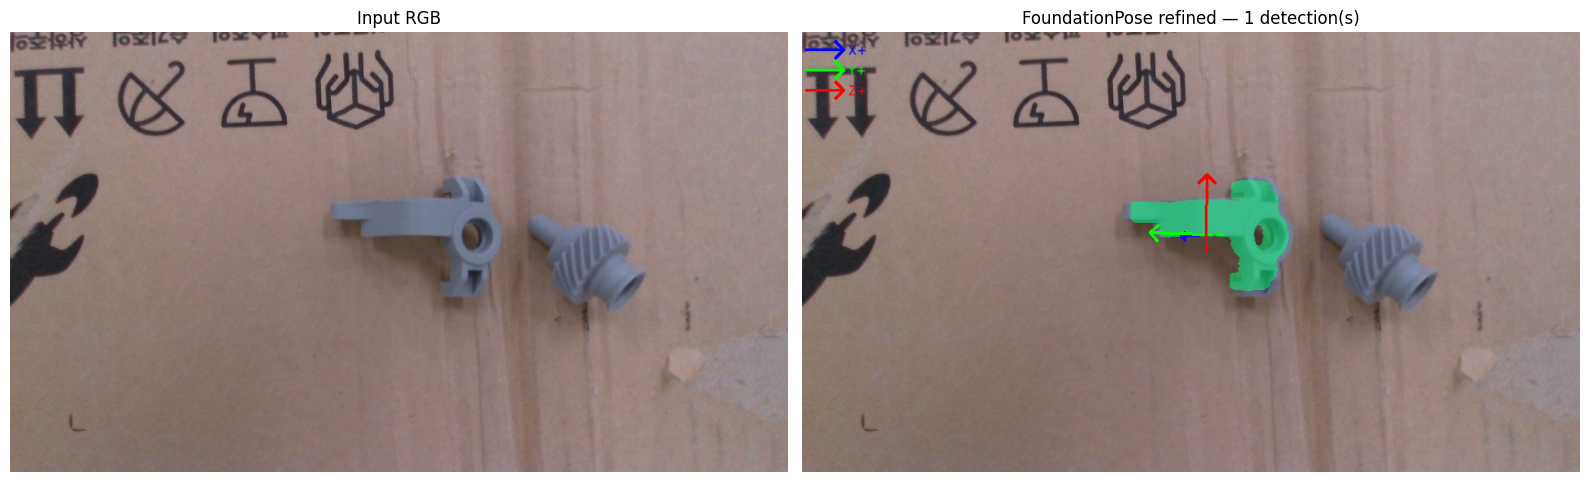

In [ ]:
def project_fp_poses(rgb, refined_results, K, cad_path, mesh_scale=1/1000.0, n_pts=4096, axis_len_m=0.02):
    """Overlay FoundationPose refined poses on the image.

    Args:
        mesh_scale: Must match the value passed to FoundationPoseRefiner (default 1/1000 for mm meshes).
        axis_len_m: Axis arrow length in metres — scale to your object (e.g. 0.02 = 20 mm).
    """
    import trimesh, cv2

    if not refined_results:
        print("No refined poses to display.")
        return

    mesh = trimesh.load_mesh(cad_path)
    # Apply the same scale used in FoundationPoseRefiner so vertices are in metres
    pts_m = mesh.sample(n_pts).astype(np.float64) * mesh_scale
    # Bbox center — matches FoundationPose's model_center = (min+max)/2
    origin_m = ((mesh.bounds[0] + mesh.bounds[1]) / 2).astype(np.float64) * mesh_scale

    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    H, W = rgb.shape[:2]

    def project_pt(p_obj_m, pose):
        p_cam = pose[:3, :3] @ p_obj_m + pose[:3, 3]
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx),
                int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx ** 2 + dy ** 2) ** 0.5))
        for k in range(0, dist, gap * 2):
            t0 = k / dist
            t1 = min((k + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas = rgb.copy()
    overlay = canvas.copy()

    for r in refined_results:
        pose = r["pose"].astype(np.float64)
        pts_cam = (pose[:3, :3] @ pts_m.T).T + pose[:3, 3]
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 2, (0, 255, 128), -1)

    canvas = cv2.addWeighted(canvas, 0.5, overlay, 0.5, 0)

    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]  # X=blue, Y=green, Z=red
    NEG_RATIO = 0.35

    for r in refined_results:
        pose = r["pose"].astype(np.float64)
        o_img = project_pt(origin_m, pose)
        if o_img is None:
            print(f"  WARNING: axis origin projects behind camera — pose t={pose[:3,3]}")
            continue
        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3)
            unit[axis_idx] = 1.0
            tip = project_pt(origin_m + unit * axis_len_m, pose)
            if tip:
                cv2.arrowedLine(canvas, o_img, tip, color, 2, tipLength=0.2)
            neg = project_pt(origin_m - unit * axis_len_m * NEG_RATIO, pose)
            if neg:
                draw_dashed_line(canvas, o_img, neg, color, 2)

    for i, (lbl, color) in enumerate([("X+", (0, 0, 255)), ("Y+", (0, 255, 0)), ("Z+", (255, 0, 0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)
        cv2.putText(canvas, lbl, (50, y + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(f"FoundationPose refined — {len(refined_results)} detection(s)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


project_fp_poses(rgb, refined, K, CAD_PATH, n_pts=8192, axis_len_m=0.02)

### Tracking on Subsequent Frames

After registration, call `fp.track()` on each new frame — no SAM-6D re-detection needed. Each active estimator independently tracks its registered object.

Call `fp.reset()` before processing a new scene or object.

In [ ]:
# --- Tracking demo ---
# Replace rgb2 / depth2 with your next-frame RGBD data.
# The estimator list from refine_from_sam6d() is retained in fp._est_list.

# rgb2   = ...   # (H, W, 3) uint8
# depth2 = ...   # (H, W) raw depth pixels

# tracked = fp.track(rgb2, depth2, K, depth_scale=DEPTH_SCALE)
# for i, t in enumerate(tracked):
#     print(f"[{i}] tracked pose:\n{t['pose']}")
#     project_fp_poses(rgb2, [{"pose": t["pose"]}], K, CAD_PATH, axis_len_m=0.02)

# --- Reset before a new scene ---
# fp.reset()

print("fp.track(rgb, depth, K, depth_scale=DEPTH_SCALE)  →  list of {pose} dicts, one per detection")
print("fp.reset()  →  clears stored estimators before a new scene")

fp.track(rgb, depth, K, depth_scale=DEPTH_SCALE)  →  list of {pose} dicts, one per detection
fp.reset()  →  clears stored estimators before a new scene


## 9. Multi-Model Detection with `SAM6D`

`SAM6D` detects and estimates poses for **M different object types simultaneously** in a single forward pass.

All shared neural network weights (SAM, DINOv2, PEM) are loaded **once** regardless of M.  Per-model metadata (rendered templates, ISM descriptors, PEM template features) are accumulated at init time — no disk I/O during inference.

Each detection in the output includes:
- `model_id` — string name of the detected model type
- `model_indices` — integer index into the `cad_path` list

In [ ]:
CAD_PATH_GEAR = "/home/joon/Downloads/cad_files/gear/helical_gear.stl"

# Template dirs are per-model — each gets its own cache folder.
TEMPLATE_DIR_KNUCKLE = "./sam6d_templates_knuckle"
TEMPLATE_DIR_GEAR    = "./sam6d_templates_helical_gear"

multi_model = SAM6D(
    cad_path=[CAD_PATH, CAD_PATH_GEAR],
    model_ids=["steering_knuckle", "transmission_gear"],
    template_dirs=[TEMPLATE_DIR_KNUCKLE, TEMPLATE_DIR_GEAR],

    # Shared model settings (loaded once for both models)
    device=DEVICE,
    sam_model_type="vit_h",
    stability_score_thresh=0.96,

    # Per-model rendering (broadcast scalar = same for all models; list = per-model)
    reset_templates=False,
    mesh_color=[(int(0.4*255), int(0.4*255), int(0.4*255)),   # knuckle: grey
                (int(0.8*255), int(0.5*255), int(0.1*255))],  # gear:    amber
    flat_shading=True,
    roughness=0.8,
    metallic=0.0,
    light_energy=600,

    # Per-model filtering thresholds (scalar = same for all models)
    det_score_thresh=0.45,
    confidence_thresh=0.25,
    pose_score_thresh=0.1,

    n_template_view=42,
    min_component_area_ratio=0.005,
    mask_overlap_thresh=0.9,

    half_precision=True,
)

[__init__()] Loading SAM (vit_h) ...
[__init__()] Init CustomSamAutomaticMaskGenerator done!
[__init__()] SAM loaded.
[__init__()] Loading DINOv2 (ISM) ...
[__init__()] Init CustomDINOv2 done!
[__init__()] Init CustomDINOv2 with full size=640 and proposal size=224 done!
[__init__()] DINOv2 loaded.
[__init__()] Loading PEM ...


load pre-trained checkpoint from: /home/joon/Projects/cnos/checkpoints/mae_pretrain_vit_base.pth


[__init__()] PEM loaded.
[__init__()] Onboarding model 1/2: steering-knuckle-thunder-truck-r1-r ...
[_maybe_render_templates_for()] Templates already at sam6d_templates_knuckle/templates, skipping render.
[_compute_ism_ref_data()] Loading cached ISM descriptors from sam6d_templates_knuckle/templates/ism_descriptors.pth
[_compute_ism_ref_data()] Loading cached ISM appearance descriptors from sam6d_templates_knuckle/templates/ism_appe_descriptors.pth
[_compute_ism_ref_data()] ISM ref data for steering-knuckle-thunder-truck-r1-r: descriptors=torch.Size([1, 42, 1024]), appe=torch.Size([1, 42, 256, 1024])
[__init__()] Extracting PEM template features for steering-knuckle-thunder-truck-r1-r ...
[__init__()] Onboarding model 2/2: helical_gear ...
[_maybe_render_templates_for()] Templates already at sam6d_templates_helical_gear/templates, skipping render.
[_compute_ism_ref_data()] Loading cached ISM descriptors from sam6d_templates_helical_gear/templates/ism_descriptors.pth
[_compute_ism_ref_d

In [ ]:
multi_results = multi_model(rgb, depth, K, depth_scale=DEPTH_SCALE)

N = len(multi_results["poses"])
print(f"Detections passing threshold: {N}\n")

if N > 0:
    for i in range(N):
        print(
            f"[{i}]  model_id={multi_results['model_ids'][i]!r:22s}"
            f"  ism={multi_results['ism_scores'][i]:.3f}"
            f"  pose_score={multi_results['pose_scores'][i]:.3f}"
        )

print(f"\nmodel_indices: {multi_results['model_indices']}")
print(f"model_ids:     {multi_results['model_ids']}")

Detections passing threshold: 2

[0]  model_id='steering_knuckle'      ism=0.636  pose_score=0.321
[1]  model_id='transmission_gear'     ism=0.678  pose_score=0.675

model_indices: [0 1]
model_ids:     ['steering_knuckle', 'transmission_gear']


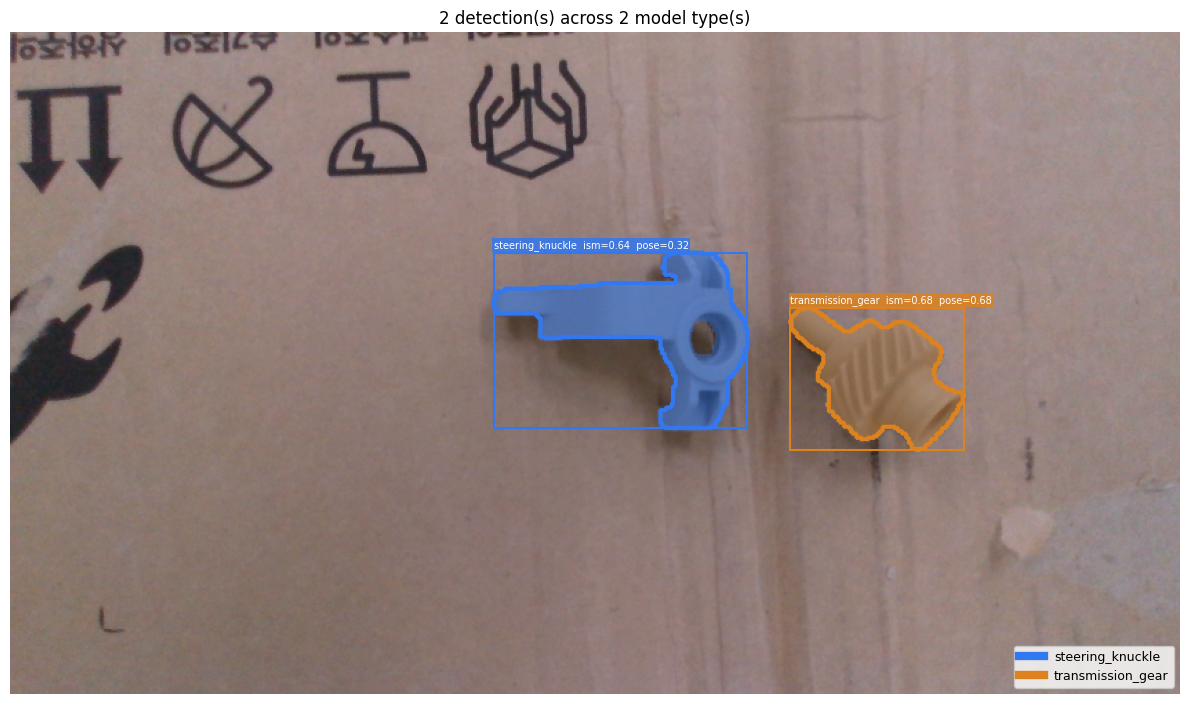

In [ ]:
def visualize_multi_model_detections(rgb, results, alpha=0.4):
    """Like visualize_detections but color-codes by model_id."""
    import cv2

    MODEL_PALETTE = {
        "steering_knuckle": np.array([50, 120, 240]),   # blue
        "transmission_gear": np.array([220, 130, 30]),  # amber
    }
    FALLBACK_COLORS = [
        np.array([220, 50,  50]),
        np.array([50,  200, 80]),
        np.array([180, 50,  220]),
        np.array([50,  220, 220]),
    ]

    masks       = results["masks"]
    boxes       = results["boxes"]
    ism_scores  = results["ism_scores"]
    pose_scores = results["pose_scores"]
    model_ids   = results.get("model_ids", ["unknown"] * len(masks))

    if len(masks) == 0:
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.imshow(rgb)
        ax.set_title("No detections")
        ax.axis("off")
        plt.show()
        return

    unique_models = sorted(set(model_ids))
    color_map = {}
    fallback_idx = 0
    for mid in unique_models:
        if mid in MODEL_PALETTE:
            color_map[mid] = MODEL_PALETTE[mid]
        else:
            color_map[mid] = FALLBACK_COLORS[fallback_idx % len(FALLBACK_COLORS)]
            fallback_idx += 1

    order   = np.argsort([-m.sum() for m in masks])
    overlay = rgb.copy().astype(float)
    for i in order:
        color = color_map[model_ids[i]]
        overlay[masks[i].astype(bool)] = (
            (1 - alpha) * overlay[masks[i].astype(bool)] + alpha * color
        )

    canvas = overlay.astype(np.uint8)
    for i in order:
        color = color_map[model_ids[i]]
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, color.tolist(), 2)

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(canvas)

    for i, (box, ism_s, pose_s, mid) in enumerate(
        zip(boxes, ism_scores, pose_scores, model_ids)
    ):
        x1, y1, x2, y2 = box
        color = color_map[mid] / 255.0
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 4,
            f"{mid}  ism={ism_s:.2f}  pose={pose_s:.2f}",
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.85, pad=1, edgecolor="none"),
        )

    # legend
    for mid, color in color_map.items():
        ax.plot([], [], color=color / 255.0, linewidth=6, label=mid)
    ax.legend(loc="lower right", fontsize=9, framealpha=0.8)

    ax.axis("off")
    ax.set_title(f"{len(masks)} detection(s) across {len(unique_models)} model type(s)")
    plt.tight_layout()
    plt.show()


visualize_multi_model_detections(rgb, multi_results)

### FoundationPose Refinement — Multi-Model

`FoundationPoseRefiner` now accepts a list of CAD paths. It loads RefineNet, ScoreNet, and the rasterizer **once**, and routes each detection to the correct mesh via the `model_indices` field in the SAM-6D results.

Each result dict includes `model_id` and `model_idx` so you can distinguish which object was refined.

In [ ]:
fp_multi = FoundationPoseRefiner(
    cad_path=[CAD_PATH, CAD_PATH_GEAR],
    model_ids=["steering_knuckle", "transmission_gear"],
    device=DEVICE,
    mesh_scale=1/1000.0,
    est_refine_iter=5,
    track_refine_iter=2,
    min_pose_score=0.0,   # scalar — same for both models; list of length 2 also accepted
    debug=0,
)

[__init__()] Loading mesh from /home/joon/Downloads/cad_files/steering_knuckle/steering-knuckle-thunder-truck-r1-r.stl (mesh_scale=0.001) ...
[__init__()] Mesh loaded: 24785 vertices, diameter≈0.0433 m.
[__init__()] Loading mesh from /home/joon/Downloads/cad_files/gear/helical_gear.stl (mesh_scale=0.001) ...
[__init__()] Mesh loaded: 27082 vertices, diameter≈0.0407 m.
[_load_models()] Loading PoseRefinePredictor ...
[__init__()] welcome
[__init__()] self.cfg: 
 lr: 0.0001
c_in: 6
zfar: .inf
debug: null
w_rot: 0.1
n_view: 1
run_id: null
use_BN: true
rot_rep: axis_angle
ckpt_dir: /home/joon/Projects/cnos/FoundationPose-main/learning/training/../../weights/2023-10-28-18-33-37/model_best.pth
exp_name: 2023-10-28-18-33-37
save_dir: /tmp/2023-10-28-18-33-37/
loss_type: l2
optimizer: adam
trans_rep: tracknet
batch_size: 64
crop_ratio: 1.2
use_normal: false
BN_momentum: 0.1
max_num_key: null
warmup_step: -1
input_resize:
- 160
- 160
max_step_val: 1000
normal_uint8: false
vis_interval: 1000
wei

In [ ]:
# Offload SAM6D weights before FoundationPose to free VRAM
multi_model.offload_to_cpu()

refined_multi = fp_multi(rgb, depth, K, multi_results, depth_scale=DEPTH_SCALE)

print(f"Refined {len(refined_multi)} detection(s)\n")
for i, r in enumerate(refined_multi):
    print(
        f"[{i}]  model_id={r['model_id']!r:22s}"
        f"  detection_idx={r['detection_idx']}"
        f"  sam6d_score={r['sam6d_score']:.3f}"
        f"  fp_score={r['fp_score']:.4f}"
    )
    print(f"     t (metres): {r['pose'][:3, 3]}")

[_load_models()] FoundationPose models loaded.
[reset_object()] self.diameter:0.04212655601396815, vox_size:0.003
[reset_object()] self.pts:torch.Size([433, 3])
[reset_object()] reset done
[make_rotation_grid()] cam_in_obs:(42, 4, 4)
[make_rotation_grid()] rot_grid:(252, 4, 4)
[make_rotation_grid()] after cluster, rot_grid:(252, 4, 4)
[make_rotation_grid()] self.rot_grid: torch.Size([252, 4, 4])
[register()] Welcome
[register()] poses:(252, 4, 4)
[register()] after viewpoint, add_errs min:-1.0
[predict()] ob_in_cams:(252, 4, 4)
[predict()] self.cfg.use_normal:False
[predict()] trans_normalizer:[0.019999999552965164, 0.019999999552965164, 0.05000000074505806], rot_normalizer:0.3490658503988659
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward d

num original candidates = 252
num of pose after clustering: 252


[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop

num original candidates = 252
num of pose after clustering: 252


[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop_data_batch()] warp done
[make_crop_data_batch()] pose batch data done
[predict()] forward start
[predict()] forward done
[predict()] making cropped data
[make_crop_data_batch()] Welcome make_crop_data_batch
[make_crop_data_batch()] make tf_to_crops done
[make_crop_data_batch()] render done
[make_crop

Refined 2 detection(s)

[0]  model_id='transmission_gear'     detection_idx=1  sam6d_score=0.675  fp_score=69.7500
     t (metres): [5.8013473e-02 1.1189960e-04 1.8392985e-01]
[1]  model_id='steering_knuckle'      detection_idx=0  sam6d_score=0.321  fp_score=86.4531
     t (metres): [0.5424805  0.01891937 0.26403952]


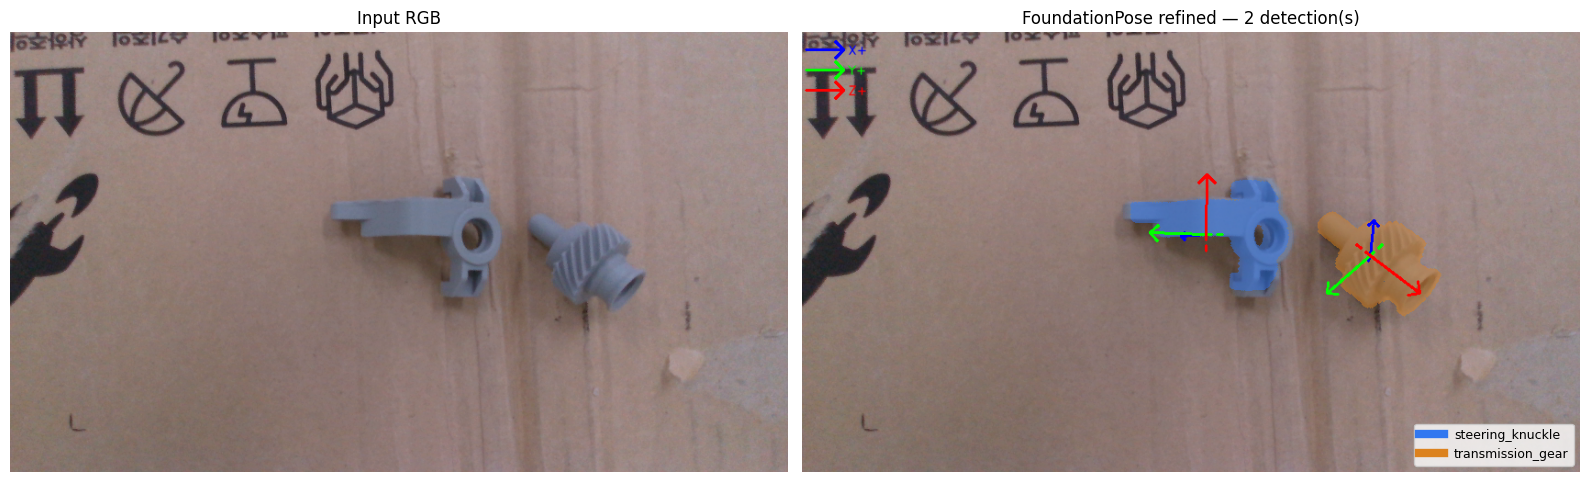

In [ ]:
import trimesh

CAD_PATHS_BY_ID = {
    "steering_knuckle": CAD_PATH,
    "transmission_gear": CAD_PATH_GEAR,
}

def project_fp_poses_multi(rgb, refined_results, K, cad_paths_by_id, mesh_scale=1/1000.0,
                            n_pts=4096, axis_len_m=0.02):
    """Project FoundationPose refined poses for multiple model types."""
    import cv2

    MODEL_COLORS = {
        "steering_knuckle": (50,  120, 240),
        "transmission_gear": (220, 130,  30),
    }
    FALLBACK = (80, 220, 80)

    if not refined_results:
        print("No refined poses to display.")
        return

    # Pre-sample point clouds per model type (once)
    pts_cache = {}
    origin_cache = {}
    for mid, cpath in cad_paths_by_id.items():
        mesh = trimesh.load_mesh(cpath)
        pts_cache[mid]    = mesh.sample(n_pts).astype(np.float64) * mesh_scale
        origin_cache[mid] = ((mesh.bounds[0] + mesh.bounds[1]) / 2).astype(np.float64) * mesh_scale

    fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
    H, W = rgb.shape[:2]

    def project_pt(p_obj_m, pose):
        p_cam = pose[:3, :3] @ p_obj_m + pose[:3, 3]
        if p_cam[2] <= 0:
            return None
        return (int(p_cam[0] * fx / p_cam[2] + cx),
                int(p_cam[1] * fy / p_cam[2] + cy))

    def draw_dashed_line(img, p1, p2, color, thickness=1, gap=6):
        dx, dy = p2[0] - p1[0], p2[1] - p1[1]
        dist = max(1, int((dx**2 + dy**2) ** 0.5))
        for k in range(0, dist, gap * 2):
            t0, t1 = k / dist, min((k + gap) / dist, 1.0)
            a = (int(p1[0] + t0 * dx), int(p1[1] + t0 * dy))
            b = (int(p1[0] + t1 * dx), int(p1[1] + t1 * dy))
            cv2.line(img, a, b, color, thickness)

    canvas  = rgb.copy()
    overlay = canvas.copy()

    for r in refined_results:
        mid  = r.get("model_id", "unknown")
        pose = r["pose"].astype(np.float64)
        pts_m = pts_cache.get(mid, list(pts_cache.values())[0])
        dot_color = MODEL_COLORS.get(mid, FALLBACK)

        pts_cam = (pose[:3, :3] @ pts_m.T).T + pose[:3, 3]
        u = (pts_cam[:, 0] * fx / pts_cam[:, 2] + cx).astype(int)
        v = (pts_cam[:, 1] * fy / pts_cam[:, 2] + cy).astype(int)
        valid = (u >= 0) & (u < W) & (v >= 0) & (v < H) & (pts_cam[:, 2] > 0)
        for ui, vi in zip(u[valid], v[valid]):
            cv2.circle(overlay, (ui, vi), 2, dot_color, -1)

    canvas = cv2.addWeighted(canvas, 0.5, overlay, 0.5, 0)

    AXIS_COLORS = [(0, 0, 255), (0, 255, 0), (255, 0, 0)]
    NEG_RATIO   = 0.35

    for r in refined_results:
        mid    = r.get("model_id", "unknown")
        pose   = r["pose"].astype(np.float64)
        origin = origin_cache.get(mid, list(origin_cache.values())[0])
        o_img  = project_pt(origin, pose)
        if o_img is None:
            continue
        for axis_idx, color in enumerate(AXIS_COLORS):
            unit = np.zeros(3); unit[axis_idx] = 1.0
            tip = project_pt(origin + unit * axis_len_m, pose)
            if tip:
                cv2.arrowedLine(canvas, o_img, tip, color, 2, tipLength=0.2)
            neg = project_pt(origin - unit * axis_len_m * NEG_RATIO, pose)
            if neg:
                draw_dashed_line(canvas, o_img, neg, color, 2)

    for i, (lbl, color) in enumerate([("X+", (0,0,255)), ("Y+", (0,255,0)), ("Z+", (255,0,0))]):
        y = 20 + i * 22
        cv2.arrowedLine(canvas, (10, y), (45, y), color, 2, tipLength=0.35)
        draw_dashed_line(canvas, (10, y), (2, y), color, 2)
        cv2.putText(canvas, lbl, (50, y + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(rgb)
    axes[0].set_title("Input RGB")
    axes[0].axis("off")
    axes[1].imshow(canvas)
    axes[1].set_title(f"FoundationPose refined — {len(refined_results)} detection(s)")
    axes[1].axis("off")

    # legend
    for mid, color in MODEL_COLORS.items():
        if mid in cad_paths_by_id:
            axes[1].plot([], [], color=np.array(color)/255.0, linewidth=6, label=mid)
    axes[1].legend(loc="lower right", fontsize=9, framealpha=0.8)

    plt.tight_layout()
    plt.show()


project_fp_poses_multi(rgb, refined_multi, K, CAD_PATHS_BY_ID, n_pts=8192, axis_len_m=0.02)